# MCMC sampling and priors

This notebook covers the MCMC tools in `psiphy.mcmc` and the prior specifications in
`psiphy.utils.prior`:

1. Priors: uniform, log-uniform, Gaussian and mixtures
2. Sampling a posterior with `MHSampler` (emcee backend)
3. Convergence diagnostics: traces, autocorrelation time, burn-in
4. Checking the result against the analytic posterior
5. Saving, reloading and extending a chain
6. Informative priors

The test problem is `NoisyLine` (a straight line with Gaussian noise). Its posterior is
Gaussian with a closed form, so every result can be checked exactly.

Related notebooks: *Nested sampling and evidence* (posterior + Bayes factors),
*Importance sampling and SMC*, *Likelihood-free inference* (simulator only).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

from psiphy.mcmc import MHSampler
from psiphy.utils.prior import UniformPrior, LogUniformPrior, GaussianPrior, MixturePrior
from psiphy.toy_models import NoisyLine
from psiphy.plotting.diagnostics import SampledDistribution, plot_triangle

np.random.seed(42)

---
## 1  Priors

Every prior in `psiphy.utils.prior` shares one interface, so the same object works with
MCMC, nested sampling, importance sampling/SMC and BOLFI:

| Method | Purpose |
|---|---|
| `sample(n)` | draws, shape `(n, ndim)` |
| `log_prob(theta)` | single point → float; batch `(n, ndim)` → `(n,)` |
| `prior_transform(u)` | unit cube → parameters (used by nested sampling) |
| `to_scipy()`, `to_torch()`, `to_sbi()` | conversion to other libraries |

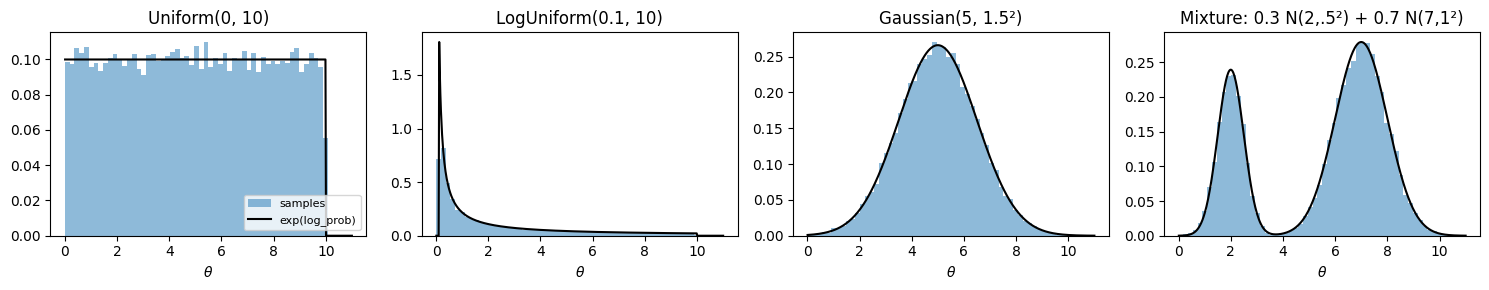

In [2]:
priors = {
    'Uniform(0, 10)':              UniformPrior([(0, 10)]),
    'LogUniform(0.1, 10)':         LogUniformPrior([(0.1, 10)]),
    'Gaussian(5, 1.5²)':           GaussianPrior([5.0], [1.5**2]),
    'Mixture: 0.3 N(2,.5²) + 0.7 N(7,1²)': MixturePrior(
        [GaussianPrior([2.0], [0.25]), GaussianPrior([7.0], [1.0])], weights=[0.3, 0.7]),
}

grid = np.linspace(0.01, 11, 500)[:, None]
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=False)
for ax, (name, p) in zip(axes, priors.items()):
    ax.hist(p.sample(20000)[:, 0], bins=60, range=(0, 11), density=True, alpha=0.5, label='samples')
    ax.plot(grid[:, 0], np.exp(p.log_prob(grid)), 'k', lw=1.5, label='exp(log_prob)')
    ax.set(title=name, xlabel=r'$\theta$')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Named bounds can be passed as a dict; the keys become `prior.names` and are picked up by
the samplers. `prior_transform` maps uniform draws on $[0,1]^d$ to the prior, which is how
nested samplers use it.

In [3]:
prior = UniformPrior({'slope': (-3, 3), 'intercept': (0, 10)})
print('names            :', prior.names)
print('log_prob (inside):', prior.log_prob([0.0, 5.0]))
print('log_prob (batch) :', prior.log_prob(np.array([[0.0, 5.0], [9.0, 5.0]])))
print('prior_transform  :', prior.prior_transform([0.5, 0.5]))

names            : ['slope', 'intercept']
log_prob (inside): -4.094344562222101
log_prob (batch) : [-4.09434456        -inf]
prior_transform  : [0. 5.]


---
## 2  Problem: fitting a noisy line

Data: $y_i = m x_i + b + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$
and known $\sigma$. With a flat prior the posterior on $(m, b)$ is Gaussian with
covariance $\sigma^2 (A^\top A)^{-1}$, where $A = [x, 1]$, centred on the least-squares fit.

analytic posterior mean: [-0.816  5.188]
analytic posterior std : [0.043 0.248]


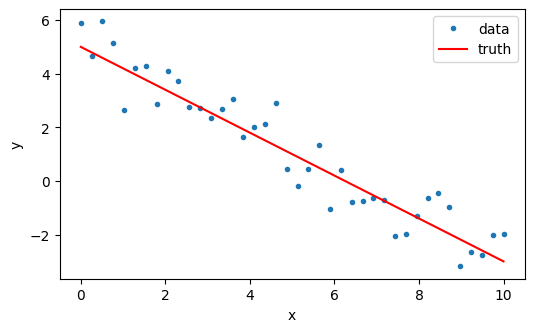

In [4]:
line = NoisyLine(Nx=40, noise_sigma=0.8)
theta_true = np.array([-0.8, 5.0])
y_obs = line.simulate(theta_true)

def log_posterior(theta):
    lp = prior.log_prob(theta)
    return lp + line.log_prob(theta, y_obs) if np.isfinite(lp) else -np.inf

# analytic posterior (flat prior, posterior well inside the box)
A = np.column_stack([line.x, np.ones_like(line.x)])
post_cov = line.noise_sigma**2 * np.linalg.inv(A.T @ A)
post_mean = np.linalg.solve(A.T @ A, A.T @ y_obs)
print('analytic posterior mean:', post_mean.round(3))
print('analytic posterior std :', np.sqrt(np.diag(post_cov)).round(3))

plt.figure(figsize=(6, 3.5))
plt.plot(line.x, y_obs, '.', label='data')
plt.plot(line.x, theta_true[0] * line.x + theta_true[1], 'r-', label='truth')
plt.xlabel('x'); plt.ylabel('y'); plt.legend()
plt.show()

---
## 3  Running `MHSampler`

`MHSampler` wraps `emcee.EnsembleSampler`. Starting from a single point, the walkers are
spread into a small Gaussian ball (`init_scale`, relative). Starting from prior draws,
pass an array of shape `(n_walkers, n_dim)`.

In [5]:
sampler = MHSampler(log_posterior, n_walkers=32, param_names=prior.names)
sampler.run(prior.sample(32), n_steps=3000, progress=False)

print('chain shape (steps, walkers, dim):', sampler.get_chain().shape)
print('mean acceptance fraction        :', sampler.acceptance_fraction.mean().round(3))

chain shape (steps, walkers, dim): (3000, 32, 2)
mean acceptance fraction        : 0.712


---
## 4  Convergence diagnostics

Walkers start spread over the whole prior and need some steps to reach the posterior.
The integrated autocorrelation time $\tau$ measures how many steps it takes for the
chain to forget its state. Common practice: discard a few $\tau$ as burn-in and run for
at least ~50 $\tau$. `discard="auto"` drops $3\,\max(\tau)$ steps.

autocorrelation time: [25.7 31.6]  → auto burn-in = 94 steps


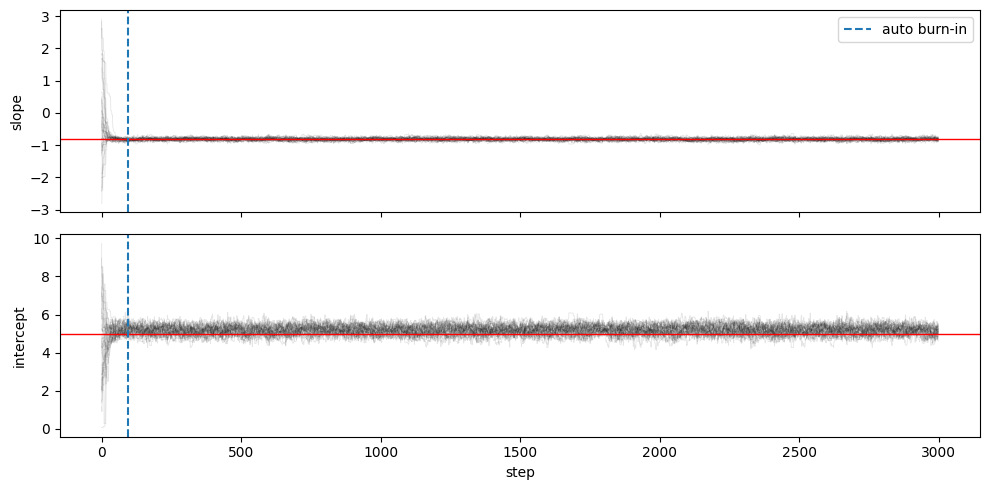

In [6]:
chain = sampler.get_chain()
tau = sampler.autocorr_time()
burn = int(3 * tau.max())
print('autocorrelation time:', tau.round(1), ' → auto burn-in =', burn, 'steps')

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, prior.names)):
    ax.plot(chain[:, :, i], 'k', alpha=0.1, lw=0.6)
    ax.axhline(theta_true[i], c='r', lw=1)
    ax.axvline(burn, c='C0', ls='--', label='auto burn-in')
    ax.set_ylabel(name)
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('step')
plt.tight_layout()
plt.show()

---
## 5  Posterior and comparison with the analytic result

In [7]:
summary = sampler.summary(discard='auto')

     param        mean         std      median      tau
     slope     -0.8164     0.04297      -0.817     25.7
 intercept       5.184      0.2475       5.186     31.6
acceptance fraction = 0.712, n_samples = 92992


MCMC mean : [-0.816  5.184]    analytic: [-0.816  5.188]
MCMC std  : [0.043 0.247]    analytic: [0.043 0.248]


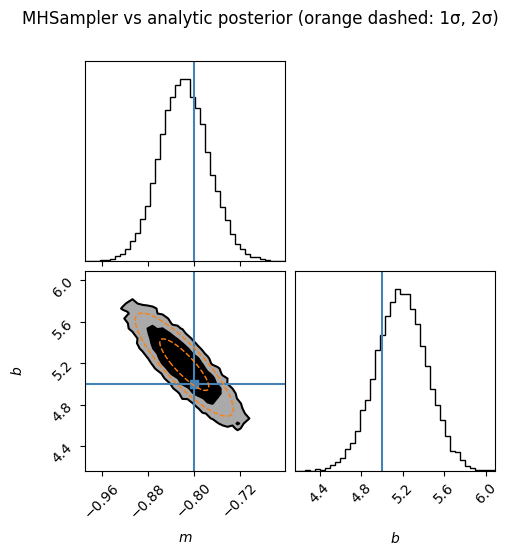

In [8]:
samples = sampler.get_chain(flat=True, discard='auto', thin=5)
print('MCMC mean :', samples.mean(0).round(3), '   analytic:', post_mean.round(3))
print('MCMC std  :', samples.std(0).round(3), '   analytic:', np.sqrt(np.diag(post_cov)).round(3))

fig = plot_triangle(samples, labels=['m', 'b'], true_values=theta_true, engine='corner',
                    bins=40, plot_datapoints=False, fill_contours=True, levels=(0.68, 0.95))
# overlay the analytic 1σ/2σ ellipse in the 2-D panel
ax = fig.axes[2]
vals, vecs = np.linalg.eigh(post_cov)
t = np.linspace(0, 2 * np.pi, 200)
for k in (1, 2):
    ell = post_mean[:, None] + vecs @ (k * np.sqrt(vals)[:, None] * np.vstack([np.cos(t), np.sin(t)]))
    ax.plot(*ell, 'C1--', lw=1)
fig.suptitle('MHSampler vs analytic posterior (orange dashed: 1σ, 2σ)', y=1.02)
plt.show()

**Why is $b$ not centred on the truth?** The MCMC result matches the analytic
posterior, and that posterior is centred on the least-squares fit to *these* 40 points.
The noise in this particular data set moves that fit away from the true line by a fraction
of a standard deviation (printed below). Every correct method follows the data; checking
for *bias* requires many data sets — see Section 7 of the *Importance sampling and SMC*
tutorial.

In [9]:
offset = (post_mean - theta_true) / np.sqrt(np.diag(post_cov))
print('least-squares fit:', post_mean.round(3), ' truth:', theta_true, ' offset (sigma):', offset.round(2))

least-squares fit: [-0.816  5.188]  truth: [-0.8  5. ]  offset (sigma): [-0.38  0.76]


The same samples plug straight into the diagnostics tools (see the *Plotting
diagnostics* tutorial) for z-scores, credible intervals and comparisons.

In [10]:
dist = SampledDistribution(samples, true_values=theta_true, labels=['m', 'b'])
for name, ci in zip(prior.names, dist.credible_intervals(levels=(68, 95))):
    print(f"{name:10s} median={ci['median']:.3f}  68% [{ci['lo68']:.3f}, {ci['hi68']:.3f}]")
print('z-scores:', np.round(dist.z_scores(), 2))

slope      median=-0.817  68% [-0.859, -0.774]
intercept  median=5.185  68% [4.941, 5.429]
z-scores: [0.38 0.75]


---
## 6  Saving, reloading and extending a chain

Pass `filename=` to store the chain in HDF5 (needs `h5py`). The file can be reloaded, and
`run(n_steps=...)` without a starting point continues from the last state — useful for
long jobs on a cluster with wall-time limits.

In [11]:
tmpdir = tempfile.mkdtemp()
fn = os.path.join(tmpdir, 'line_chain.h5')

s1 = MHSampler(log_posterior, n_walkers=32, filename=fn)
s1.run(prior.sample(32), n_steps=500)
print('first job :', s1.n_steps, 'steps')

# later, e.g. in a new job:
s2 = MHSampler.load(fn, log_prob_fn=log_posterior)
s2.run(n_steps=1000)
print('after resume:', s2.n_steps, 'steps stored in', os.path.basename(fn))

first job : 500 steps


after resume: 1500 steps stored in line_chain.h5


---
## 7  Informative priors

Swapping the prior is a one-line change. A Gaussian prior on the intercept (say from an
earlier measurement) tightens the intercept and, through the correlation, the slope.

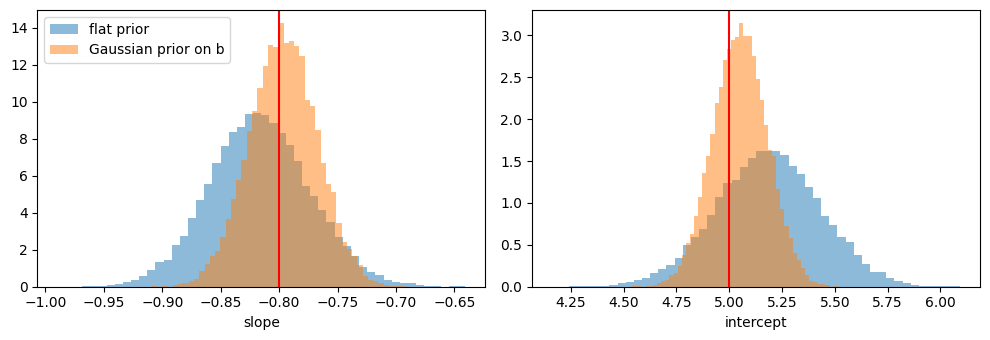

std flat       : [0.043 0.247]
std informative: [0.029 0.128]


In [12]:
prior_inf = GaussianPrior(mean=[0.0, 5.0], cov=[10.0**2, 0.15**2], names=['slope', 'intercept'])
log_post_inf = lambda t: prior_inf.log_prob(t) + line.log_prob(t, y_obs)

s_inf = MHSampler(log_post_inf, n_walkers=32).run(prior.sample(32), n_steps=3000)
samples_inf = s_inf.get_chain(flat=True, discard='auto', thin=5)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, (ax, name) in enumerate(zip(axes, prior.names)):
    ax.hist(samples[:, i], bins=50, density=True, alpha=0.5, label='flat prior')
    ax.hist(samples_inf[:, i], bins=50, density=True, alpha=0.5, label='Gaussian prior on b')
    ax.axvline(theta_true[i], c='r')
    ax.set_xlabel(name)
axes[0].legend()
plt.tight_layout()
plt.show()
print('std flat       :', samples.std(0).round(3))
print('std informative:', samples_inf.std(0).round(3))

---
## Summary

| Task | Code |
|---|---|
| Define a prior | `UniformPrior({...})`, `LogUniformPrior`, `GaussianPrior`, `MixturePrior` |
| Run MCMC | `MHSampler(log_prob, n_walkers=32).run(theta_init, n_steps=...)` |
| Diagnose | `autocorr_time()`, `acceptance_fraction`, trace of `get_chain()` |
| Samples | `get_chain(flat=True, discard='auto', thin=...)` |
| Summary | `summary()` |
| Checkpoint / resume | `filename='chain.h5'`, `MHSampler.load(...)`, `run(n_steps=...)` |

Parallel evaluation: pass `pool=` (any object with a `map` method, e.g. a
`multiprocessing.Pool`).